<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide](README.md)

# 01 · A spike, a shift, or an unusual pattern?

A telemetry trace can contain several kinds of surprise. Does one large reading
look unusual against the entire record, against its current operating level, or
as part of a short pattern? Those are different questions, and they can produce
different answers on the same samples.

We will construct **240 synthetic one-minute readings**, then use the real
`vgi-anomaly` worker through Haybarn and VGI to compare point outliers, automatic
change points, and matrix-profile motifs and discords. SQL creates and transforms
the data; Python only connects, validates and presents the results.

**Provenance:** this is a deterministic teaching signal, not measured equipment data.
Values are in invented **telemetry units (TU)**. A repeating cycle, a level shift
and a spike are deliberately inserted. They are construction markers, not real
incident labels, and no detector result establishes a cause.

## Choose the scale of the question

`WINDOW_SAMPLES` is a subsequence length: 24 readings cover 24 one-minute sample
slots, with 23 minutes between the first and last timestamps. `ZSCORE_THRESHOLD`
is an absolute cutoff in **population standard deviations**, applied both globally
and within automatically detected segments.

Edit the visible parameters, then **Restart Kernel → Run All**. Accepted notebook
ranges are narrower than the worker's API so this 240-sample demonstration stays
readable. The final experiment changes only the subsequence window.

In [1]:
WINDOW_SAMPLES = 24  # Integer 6–60; one reading per minute. Experiment: 48.
ZSCORE_THRESHOLD = 3.0  # Finite number 1.5–5.0; flag when absolute z > threshold.

In [2]:
import math
import os

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
from notebook_support import (  # noqa: E402 -- configure telemetry before loading helpers.
    COLORS,
    finish_chart,
    prose,
    set_theme,
    validate_parameters,
)

validate_parameters(WINDOW_SAMPLES, ZSCORE_THRESHOLD)
os.environ["NUMBA_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC", "threads": 2})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-anomaly/notebooks/.venv/lib/python3.13/site-packages/sql/parse.py:339: SyntaxWarning: invalid escape sequence '\:'
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-anomaly/notebooks/.venv/lib/python3.13/site-packages/sql/parse.py:369: SyntaxWarning: invalid escape sequence '\:'
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-anomaly/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-anomaly/notebooks/pyproject.toml.

## Attach the real worker

The literal command below runs the published **v0.5.0** Git revision through `uvx`,
with the compatible VGI SDK pinned. No checkout installation is needed. The notebook
environment supplies published Haybarn and plotting packages; Git and uv/uvx must be
on PATH. First use downloads and caches the worker. Setup caps numerical threads
without changing detector logic. A cold matrix-profile call may pause while the
worker compiles its numerical kernel. See [setup and upgrade instructions](README.md).


In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'anomaly' AS anomaly (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-anomaly@b933ef6e41dce2ef151e7c6f109f3a8f724f0291 vgi-anomaly-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Build a trace whose ingredients we know

The UTC interval is **2026-01-01 00:00 inclusive to 04:00 exclusive**, sampled once
per minute. It is a fixed illustrative clock, not a collection timestamp.
`sample_id` is a unique, zero-based position. The formula adds a 12-minute repeated
cycle to a 20 TU base, then adds 12 TU from minute 120 and a one-sample 8 TU spike
at minute 180. These constants keep the input fixed during the window experiment.

Every detector receives exactly one numeric column, with `ORDER BY sample_id`
**inside** its input query. Returned indices are positions in that ordered input;
they can be joined back to `sample_id` here because the IDs are contiguous.

In [4]:
%%sql coverage <<
CREATE OR REPLACE TABLE telemetry AS
SELECT i AS sample_id,
       TIMESTAMP '2026-01-01 00:00:00' + i * INTERVAL '1 minute' AS observed_at_utc,
       (20.0 + [0,1,2,3,2,1,0,-1,-2,-3,-2,-1][i % 12 + 1]
        + CASE WHEN i >= 120 THEN 12.0 ELSE 0.0 END
        + CASE WHEN i = 180 THEN 8.0 ELSE 0.0 END)::DOUBLE AS reading_tu,
       i = 120 AS injected_shift_start,
       i = 180 AS injected_spike
FROM range(240) r(i);
SELECT count(*) AS samples, count(DISTINCT sample_id) AS unique_positions,
       count(*) FILTER (WHERE reading_tu IS NULL OR NOT isfinite(reading_tu)) AS invalid_values,
       min(observed_at_utc) AS first_sample_utc,
       max(observed_at_utc) AS last_sample_utc,
       min(reading_tu) AS minimum_tu, max(reading_tu) AS maximum_tu
FROM telemetry;

In [5]:
# Read the DataFrame captured by the preceding JupySQL cell.
coverage: pd.DataFrame = globals()["coverage"]
display(coverage)
c = coverage.iloc[0]
assert c.samples == c.unique_positions and c.invalid_values == 0
prose(
    f"The input has **{int(c.samples)} unique ordered samples**, no missing or non-finite readings, "
    f"and spans **{c.minimum_tu:g}–{c.maximum_tu:g} TU**. "
    "The last timestamp is 03:59 UTC; the exclusive end is 04:00 UTC. "
    "No interpolation or missing-value substitution is performed."
)

,samples,unique_positions,invalid_values,first_sample_utc,last_sample_utc,minimum_tu,maximum_tu
0,240,240,0,2026-01-01,2026-01-01 03:59:00,17.0,40.0


The input has **240 unique ordered samples**, no missing or non-finite readings, and spans **17–40 TU**. The last timestamp is 03:59 UTC; the exclusive end is 04:00 UTC. No interpolation or missing-value substitution is performed.

In [6]:
%%sql trace <<
SELECT *, sample_id AS elapsed_minutes
FROM telemetry ORDER BY sample_id;

findfont: Failed to find font weight semibold for Arial, now using 700.


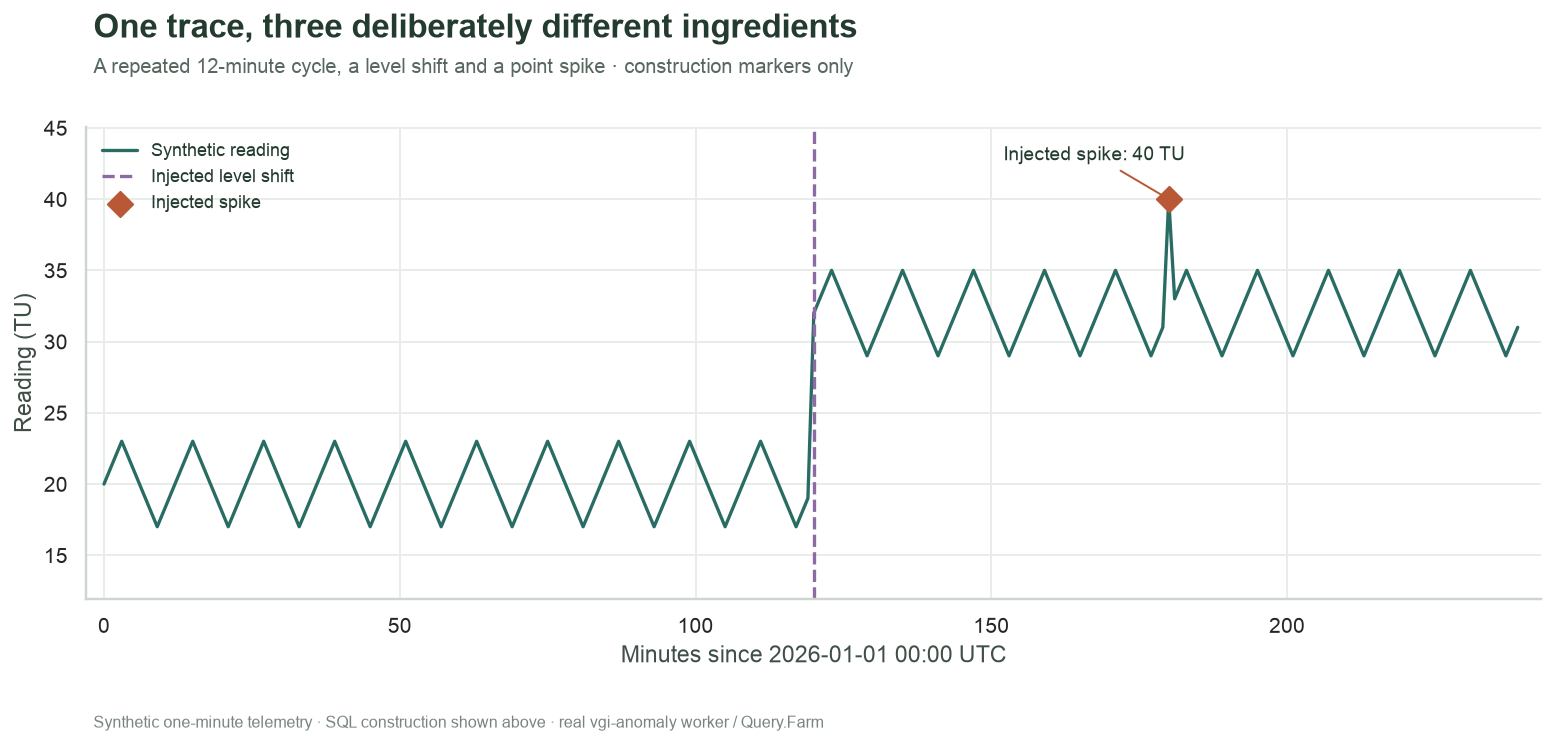

In [7]:
# Read the DataFrame captured by the preceding JupySQL cell.
trace: pd.DataFrame = globals()["trace"]
fig, ax = plt.subplots(figsize=(11.5, 5.3))
ax.plot(trace.elapsed_minutes, trace.reading_tu, color=COLORS["signal"], label="Synthetic reading")
shift = trace.loc[trace.injected_shift_start].iloc[0]
spike = trace.loc[trace.injected_spike].iloc[0]
ax.axvline(shift.elapsed_minutes, color=COLORS["change"], linestyle="--", label="Injected level shift")
ax.scatter(
    [spike.elapsed_minutes],
    [spike.reading_tu],
    s=85,
    color=COLORS["spike"],
    marker="D",
    zorder=5,
    label="Injected spike",
)
ax.annotate(
    f"Injected spike: {spike.reading_tu:g} TU",
    (spike.elapsed_minutes, spike.reading_tu),
    xytext=(-85, 20),
    textcoords="offset points",
    fontsize=10,
    arrowprops={"arrowstyle": "-", "color": COLORS["spike"]},
)
ax.set(xlabel="Minutes since 2026-01-01 00:00 UTC", ylabel="Reading (TU)", xlim=(-3, 243))
ax.margins(y=0.22)
ax.legend(loc="upper left", ncol=1, fontsize=9)
finish_chart(
    fig,
    "One trace, three deliberately different ingredients",
    "A repeated 12-minute cycle, a level shift and a point spike · construction markers only",
)

## Does the whole-record distribution hide a local spike?

First ask the worker for **point outliers** and for **automatic segment boundaries**.
`zscore_anomalies` flags readings with `abs(value − mean) / population_std > threshold`.
The automatic `change_points` path uses PELT with an RBF cost and a `log(n)` penalty;
we do not tell it how many breaks to return. A boundary marks the first sample
of a new segment, and the terminal end-of-series sentinel is excluded.

These calls buffer the complete ordered series. They are retrospective analyses,
not streaming alerts: future samples can influence earlier results.

In [8]:
%%sql detector_status <<
CREATE OR REPLACE TABLE global_flags AS
SELECT "index" AS sample_id
FROM anomaly.zscore_anomalies(
    (SELECT reading_tu FROM telemetry ORDER BY sample_id),
    threshold := {{ ZSCORE_THRESHOLD }}
);
CREATE OR REPLACE TABLE detected_breaks AS
SELECT "index" AS break_at
FROM anomaly.change_points((SELECT reading_tu FROM telemetry ORDER BY sample_id));
SELECT 'whole-series z-score' AS detector, count(*) AS result_rows,
       count(*) FILTER (WHERE sample_id IS NULL) AS null_rows,
       list(sample_id ORDER BY sample_id) FILTER (WHERE sample_id IS NOT NULL) AS positions
FROM global_flags
UNION ALL
SELECT 'automatic change points', count(*),
       count(*) FILTER (WHERE break_at IS NULL),
       list(break_at ORDER BY break_at) FILTER (WHERE break_at IS NOT NULL)
FROM detected_breaks;

In [9]:
# Read the DataFrame captured by the preceding JupySQL cell.
detector_status: pd.DataFrame = globals()["detector_status"]
display(detector_status)
assert detector_status.null_rows.eq(0).all(), "A detector returned an invalid-series NULL row."
global_count = int(detector_status.iloc[0].result_rows)
break_count = int(detector_status.iloc[1].result_rows)
prose(
    f"The worker returned **{global_count} whole-series point flags** "
    f"and an **automatic boundary count of {break_count}**. "
    "For this validated nonempty input, zero result rows mean no matches. A NULL result row would mean "
    "an invalid series and stops this notebook; it is not treated as zero detections. "
    "The positions aggregate is NULL when there are no rows to collect."
)

,detector,result_rows,null_rows,positions
0,whole-series z-score,0,0,<NA>
1,automatic change points,1,0,[120]


The worker returned **0 whole-series point flags** and an **automatic boundary count of 1**. For this validated nonempty input, zero result rows mean no matches. A NULL result row would mean an invalid series and stops this notebook; it is not treated as zero detections. The positions aggregate is NULL when there are no rows to collect.

Now assign each sample to the segment chosen by the worker and apply the **same
worker z-score function within each segment**. The grouped scalar interface accepts
an ordered `DOUBLE[]`; its returned positions are local to that segment. Adding
the segment's first `sample_id` maps them back to this contiguous trace.

The table also exposes segment sample counts, means and population standard
deviations. A larger whole-record spread can conceal a local deviation. Segmenting
on the same data is an exploratory choice, not independent confirmation of a fault.

In [10]:
%%sql segments <<
CREATE OR REPLACE TABLE segmented AS
SELECT t.*, (SELECT count(*) FROM detected_breaks b WHERE b.break_at <= t.sample_id) AS regime
FROM telemetry t;
CREATE OR REPLACE TABLE regime_summary AS
SELECT regime, min(sample_id) AS first_position, max(sample_id) AS last_position,
       count(*) AS samples, avg(reading_tu) AS mean_tu, stddev_pop(reading_tu) AS std_tu,
       anomaly.zscore_anomalies(array_agg(reading_tu ORDER BY sample_id), {{ ZSCORE_THRESHOLD }}) AS local_flags
FROM segmented GROUP BY regime;
CREATE OR REPLACE TABLE regime_flags AS
SELECT regime, first_position + unnest(local_flags) AS sample_id FROM regime_summary;
SELECT regime, first_position, last_position, samples, round(mean_tu, 3) AS mean_tu,
       round(std_tu, 3) AS population_std_tu, local_flags,
       [first_position + i FOR i IN local_flags] AS original_positions
FROM regime_summary ORDER BY first_position;

In [11]:
# Read the DataFrame captured by the preceding JupySQL cell.
segments: pd.DataFrame = globals()["segments"]
display(segments)
assert segments.local_flags.notna().all()
assert (segments.last_position - segments.first_position + 1).eq(segments.samples).all()
prose(
    f"The worker-defined segments contain **{int(segments.samples.sum())} samples in total**. "
    "`local_flags` counts from zero inside each segment; `original_positions` is the corresponding "
    "index in the full trace. Empty lists are valid no-match results. "
    "Next, compare the distances from the two reference distributions on identical vertical scales."
)

,regime,first_position,last_position,samples,mean_tu,population_std_tu,local_flags,original_positions
0,0,0,119,120,20.000,1.780,[],[]
1,1,120,239,120,32.067,1.922,[60],[180]


The worker-defined segments contain **240 samples in total**. `local_flags` counts from zero inside each segment; `original_positions` is the corresponding index in the full trace. Empty lists are valid no-match results. Next, compare the distances from the two reference distributions on identical vertical scales.

In [12]:
%%sql scored <<
WITH whole AS (
    SELECT avg(reading_tu) AS mean_tu, stddev_pop(reading_tu) AS std_tu FROM telemetry
)
SELECT s.sample_id, s.reading_tu, s.regime, s.injected_spike, s.injected_shift_start,
       abs(s.reading_tu - w.mean_tu) / nullif(w.std_tu, 0) AS global_abs_z,
       abs(s.reading_tu - r.mean_tu) / nullif(r.std_tu, 0) AS regime_abs_z,
       s.sample_id IN (SELECT sample_id FROM global_flags) AS global_flag,
       s.sample_id IN (SELECT sample_id FROM regime_flags) AS regime_flag
FROM segmented s JOIN regime_summary r USING (regime) CROSS JOIN whole w
ORDER BY s.sample_id;

findfont: Failed to find font weight semibold for Arial, now using 700.


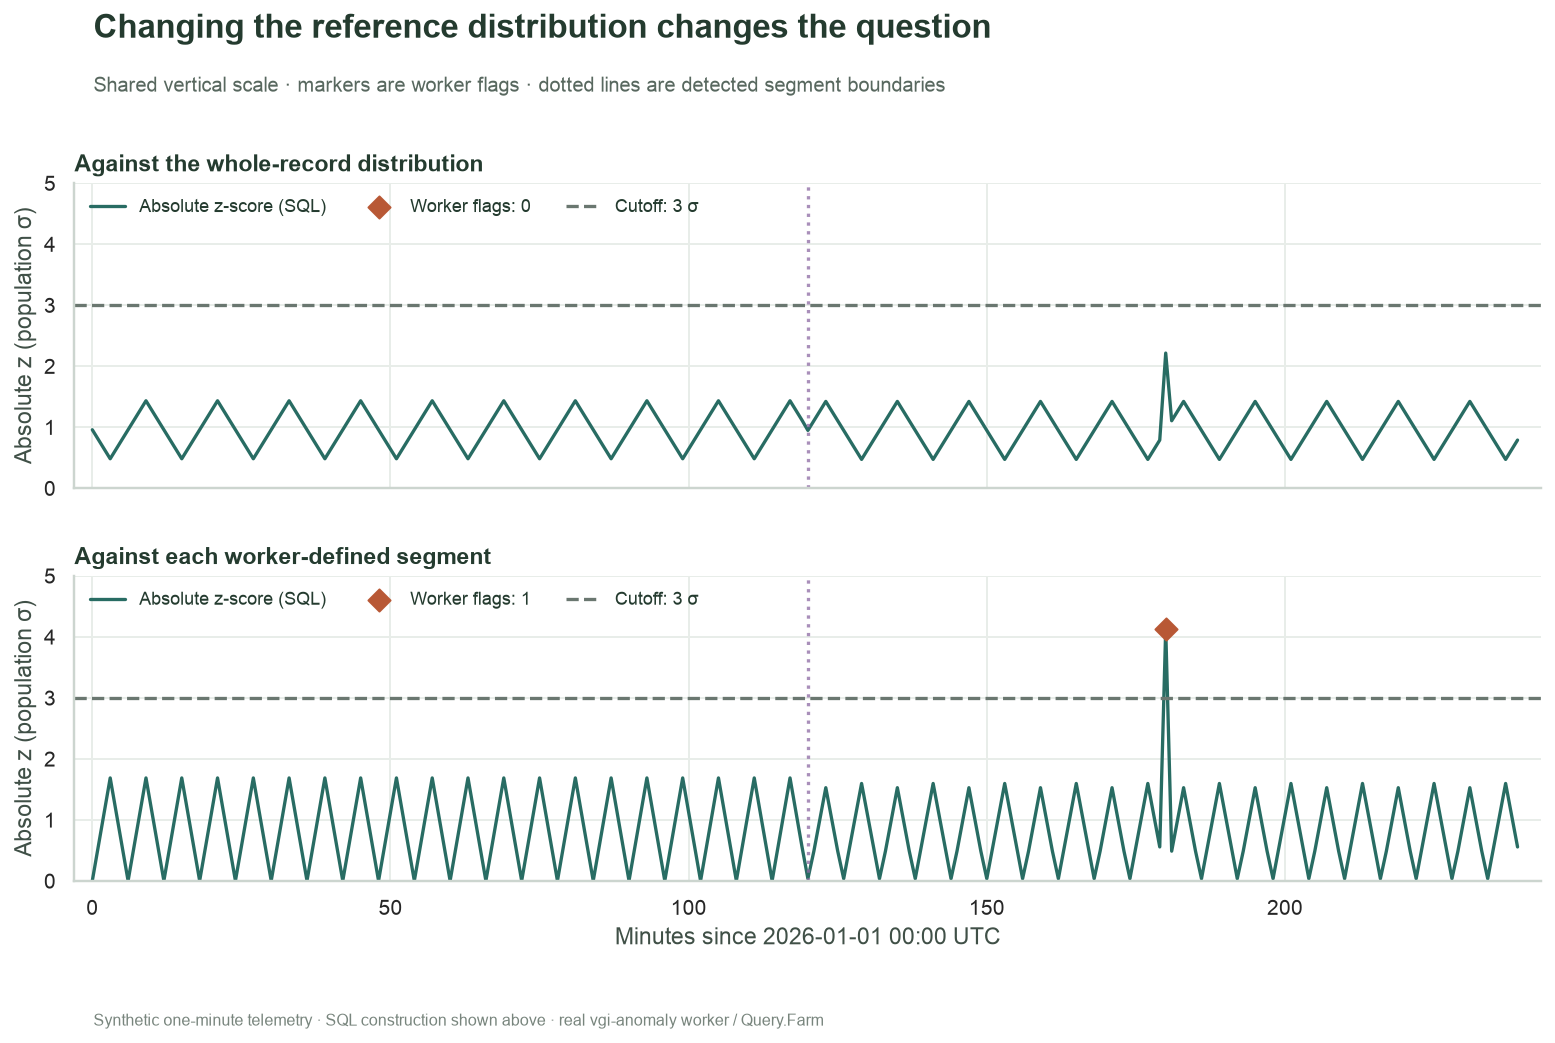

In [13]:
# Read the DataFrame captured by the preceding JupySQL cell.
scored: pd.DataFrame = globals()["scored"]
# SQL exposes score magnitudes; boolean flags still come from the real worker.
assert scored.global_flag.eq(scored.global_abs_z.gt(ZSCORE_THRESHOLD)).all()
assert scored.regime_flag.eq(scored.regime_abs_z.gt(ZSCORE_THRESHOLD)).all()
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7.5), sharex=True, sharey=True)
for ax, score, flag, title in zip(
    axes,
    ["global_abs_z", "regime_abs_z"],
    ["global_flag", "regime_flag"],
    ["Against the whole-record distribution", "Against each worker-defined segment"],
    strict=True,
):
    ax.plot(scored.sample_id, scored[score], color=COLORS["signal"], label="Absolute z-score (SQL)")
    points = scored.loc[scored[flag]]
    ax.scatter(
        points.sample_id,
        points[score],
        marker="D",
        s=65,
        color=COLORS["spike"],
        label=f"Worker flags: {len(points)}",
        zorder=4,
    )
    ax.axhline(ZSCORE_THRESHOLD, linestyle="--", color="#6A7770", label=f"Cutoff: {ZSCORE_THRESHOLD:g} σ")
    for b in segments.first_position.iloc[1:]:
        ax.axvline(b, color=COLORS["change"], linestyle=":", alpha=0.75)
    ax.set(title=title, ylabel="Absolute z (population σ)", ylim=(0, max(5, scored.regime_abs_z.max() + 0.7)))
    ax.legend(loc="upper left", ncol=3, fontsize=9)
axes[-1].set(xlabel="Minutes since 2026-01-01 00:00 UTC", xlim=(-3, 243))
finish_chart(
    fig,
    "Changing the reference distribution changes the question",
    "Shared vertical scale · markers are worker flags · dotted lines are detected segment boundaries",
)

In [14]:
spike_result = scored.loc[scored.injected_spike].iloc[0]
prose(
    f"At the injected spike (minute **{int(spike_result.sample_id)}**), the absolute score is "
    f"**{spike_result.global_abs_z:.2f} σ globally** and **{spike_result.regime_abs_z:.2f} σ within its segment**. "
    f"At the selected cutoff of **{ZSCORE_THRESHOLD:g} σ**, the worker "
    f"**{'flags' if spike_result.global_flag else 'does not flag'}** it globally and "
    f"**{'flags' if spike_result.regime_flag else 'does not flag'}** it within its segment. "
    "The segmentation changes the baseline; it does not make the spike's cause known. "
    "These scores are distances, not calibrated probabilities or guaranteed false-alarm rates."
)

At the injected spike (minute **180**), the absolute score is **2.21 σ globally** and **4.13 σ within its segment**. At the selected cutoff of **3 σ**, the worker **does not flag** it globally and **flags** it within its segment. The segmentation changes the baseline; it does not make the spike's cause known. These scores are distances, not calibrated probabilities or guaranteed false-alarm rates.

## Which short shape is hardest to match elsewhere?

A **matrix profile** measures each window's distance to its nearest non-trivial
neighbor after z-normalizing both windows. Low distance means a repeated shape
(a *motif*); the largest distance identifies a *discord*. The distance is
dimensionless z-normalized Euclidean distance, not TU and not a probability.

Normalization removes a window's overall level and scale, so the same cycle can
match across the two operating levels. A window crossing the shift or containing
the spike changes shape. Nearby heavily overlapping matches are excluded by the
matrix-profile method. Ties can occur in this deliberately periodic trace: the
worker returns the first extremum, not every equally good motif or discord.

We materialize the full profile once, and separately ask the real worker for its
top motif and discord. The final table joins those starts back to timestamps and
checks their profile distances. No detector is reimplemented in Python.

In [15]:
%%sql windows <<
CREATE OR REPLACE TABLE profile AS
SELECT "index" AS start_position, distance
FROM anomaly.matrix_profile(
    (SELECT reading_tu FROM telemetry ORDER BY sample_id),
    window_size := {{ WINDOW_SAMPLES }}
);
CREATE OR REPLACE TABLE selected_windows AS
SELECT 'Discord' AS kind, "index" AS start_position
FROM anomaly.discord_index(
    (SELECT reading_tu FROM telemetry ORDER BY sample_id),
    window_size := {{ WINDOW_SAMPLES }}
)
UNION ALL
SELECT 'Motif', "index"
FROM anomaly.motif_index(
    (SELECT reading_tu FROM telemetry ORDER BY sample_id),
    window_size := {{ WINDOW_SAMPLES }}
);
SELECT w.kind, w.start_position, w.start_position + {{ WINDOW_SAMPLES }} - 1 AS last_position,
       t.observed_at_utc AS first_sample_utc,
       t.observed_at_utc + {{ WINDOW_SAMPLES }} * INTERVAL '1 minute' AS slot_end_exclusive_utc,
       p.distance AS profile_distance,
       180 BETWEEN w.start_position AND w.start_position + {{ WINDOW_SAMPLES }} - 1 AS contains_injected_spike,
       w.start_position < 120 AND 120 <= w.start_position + {{ WINDOW_SAMPLES }} - 1 AS crosses_injected_shift
FROM selected_windows w JOIN profile p USING (start_position)
JOIN telemetry t ON t.sample_id = w.start_position ORDER BY w.kind;

In [16]:
# Read the DataFrame captured by the preceding JupySQL cell.
windows: pd.DataFrame = globals()["windows"]
display(windows)
assert len(windows) == 2 and windows.start_position.notna().all()
prose(
    f"Each selected window contains **{WINDOW_SAMPLES} readings**. "
    "`last_position` is included; `slot_end_exclusive_utc` is the end of the last one-minute sample slot. "
    "The construction-overlap columns describe which injected ingredients lie in each window; "
    "they are not classification accuracy scores."
)

,kind,start_position,last_position,first_sample_utc,slot_end_exclusive_utc,profile_distance,contains_injected_spike,crosses_injected_shift
0,Discord,109,132,2026-01-01 01:49:00,2026-01-01 02:13:00,5.645,False,True
1,Motif,0,23,2026-01-01 00:00:00,2026-01-01 00:24:00,0.000,False,False


Each selected window contains **24 readings**. `last_position` is included; `slot_end_exclusive_utc` is the end of the last one-minute sample slot. The construction-overlap columns describe which injected ingredients lie in each window; they are not classification accuracy scores.

In [17]:
%%sql profile_rows <<
SELECT start_position, distance FROM profile ORDER BY start_position;

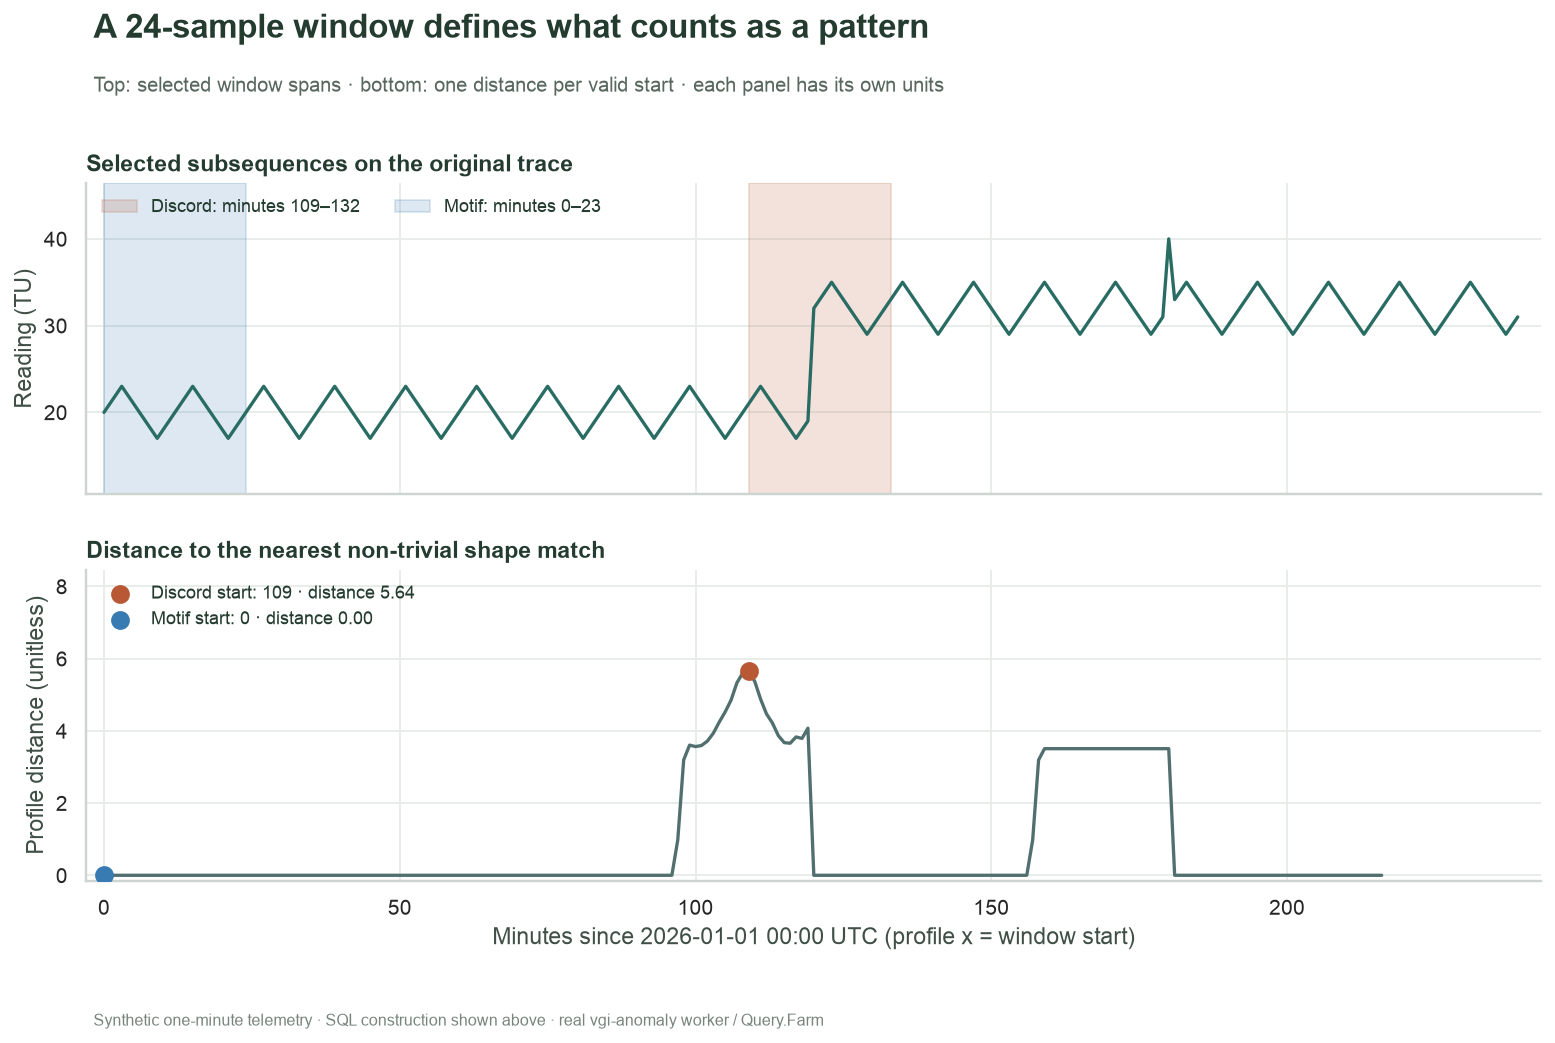

In [18]:
# Read the DataFrame captured by the preceding JupySQL cell.
profile_rows: pd.DataFrame = globals()["profile_rows"]
assert len(profile_rows) == len(trace) - WINDOW_SAMPLES + 1
assert profile_rows.start_position.tolist() == list(range(len(profile_rows)))
assert profile_rows.distance.map(math.isfinite).all() and profile_rows.distance.ge(0).all()
discord = windows.loc[windows.kind.eq("Discord")].iloc[0]
motif = windows.loc[windows.kind.eq("Motif")].iloc[0]
assert abs(discord.profile_distance - profile_rows.distance.max()) < 1e-6
assert abs(motif.profile_distance - profile_rows.distance.min()) < 1e-6
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7.5), sharex=True)
axes[0].plot(trace.elapsed_minutes, trace.reading_tu, color=COLORS["signal"])
axes[0].set(title="Selected subsequences on the original trace", ylabel="Reading (TU)")
axes[1].plot(profile_rows.start_position, profile_rows.distance, color="#526F70")
axes[1].set(title="Distance to the nearest non-trivial shape match", ylabel="Profile distance (unitless)")
for row, color in [(discord, COLORS["spike"]), (motif, COLORS["motif"])]:
    lo, hi = int(row.start_position), int(row.last_position) + 1
    axes[0].axvspan(lo, hi, color=color, alpha=0.17, label=f"{row.kind}: minutes {lo}–{hi - 1}")
    axes[1].scatter(
        lo,
        row.profile_distance,
        color=color,
        s=75,
        zorder=4,
        label=f"{row.kind} start: {lo} · distance {row.profile_distance:.2f}",
    )
axes[0].legend(loc="upper left", ncol=2, fontsize=9)
axes[1].legend(loc="upper left", ncol=1, fontsize=9)
axes[1].set(xlabel="Minutes since 2026-01-01 00:00 UTC (profile x = window start)", xlim=(-3, 243))
axes[0].margins(y=0.28)
axes[1].set_ylim(-0.15, max(profile_rows.distance.max() * 1.5, 1.0))
finish_chart(
    fig,
    f"A {WINDOW_SAMPLES}-sample window defines what counts as a pattern",
    "Top: selected window spans · bottom: one distance per valid start · each panel has its own units",
)

In [19]:
features = []
if discord.contains_injected_spike:
    features.append("contains the injected spike")
if discord.crosses_injected_shift:
    features.append("crosses the injected shift")
feature_text = " and ".join(features) if features else "contains neither construction marker"
prose(
    f"The highest-profile window starts at minute **{int(discord.start_position)}**, ends at minute "
    f"**{int(discord.last_position)}** inclusive, and {feature_text}. Its nearest-match distance is "
    f"**{discord.profile_distance:.3f}**, versus **{motif.profile_distance:.3f}** for the returned motif. "
    f"The profile has **{len(profile_rows)} valid window starts**. "
    "The discord start is the beginning of a window, not an estimated incident timestamp. "
    "A high relative distance identifies an unusual shape in this record; it provides no causal diagnosis."
)

The highest-profile window starts at minute **109**, ends at minute **132** inclusive, and crosses the injected shift. Its nearest-match distance is **5.645**, versus **0.000** for the returned motif. The profile has **217 valid window starts**. The discord start is the beginning of a window, not an estimated incident timestamp. A high relative distance identifies an unusual shape in this record; it provides no causal diagnosis.

## Experiment: does a longer view point to the same interval?

Change **only `WINDOW_SAMPLES` from `24` to `48`**, then restart and run all.
Before running, predict whether a window spanning four cycles will select the
same start as one spanning two. Keep `ZSCORE_THRESHOLD = 3.0` and the synthetic
construction unchanged.

Compare the **selected-window table** and the **profile chart**: record the discord
start/end, whether it overlaps each construction marker, and the number of valid
starts. The point flags and automatic segment boundaries should stay the same
because neither takes `WINDOW_SAMPLES`. The next result block records the current
run's comparison values.

Distances for different window lengths are not on a directly comparable anomaly
severity scale: they sum discrepancies over different numbers of samples. A
changed discord means sensitivity to the question's duration, not that one
window has uncovered the true cause. Restore **`WINDOW_SAMPLES = 24`** to reset.
The [runner command](README.md#repeatable-execution) saves the 48-sample experiment
separately and preserves this successful default.

In [20]:
prose(
    f"**Current run:** window **{WINDOW_SAMPLES} samples**; **{len(profile_rows)} profile starts**; "
    f"discord **[{int(discord.start_position)}, {int(discord.last_position)}]** inclusive; "
    f"global flag count **{global_count}**; segmented flag count **{int(scored.regime_flag.sum())}**; "
    f"automatic boundary count **{break_count}**. "
    "Use these returned values to compare runs; the fixed SQL data construction makes the "
    "one-parameter comparison reproducible."
)

**Current run:** window **24 samples**; **217 profile starts**; discord **[109, 132]** inclusive; global flag count **0**; segmented flag count **1**; automatic boundary count **1**. Use these returned values to compare runs; the fixed SQL data construction makes the one-parameter comparison reproducible.

[Notebook guide](README.md) · [Worker source and SQL reference](https://github.com/Query-farm/vgi-anomaly) ·
[Notebook standard](STANDARD.md)

This example demonstrates detector meanings on a known synthetic construction.
Real telemetry needs its own treatment of missingness, irregular sampling,
operating context and validation against independent evidence. The final folded
cell closes this run's connection and releases its worker.

In [21]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>